# Phase 6 - Distribution models: predicting the range, not just one number

A point prediction says *"24 points."* A **distribution** says *"most likely around 24, 1-in-5 chance of 30+, small chance of under 12."*
That's far more useful - for example, for deciding whether a player goes **over or under** a line.

Code: `src/models/distributions.py`. Every model uses the same **center** (Phase 5's best linear model) and differs only in the **shape and width** around it:

| Model | Shape | Width |
|---|---|---|
| Normal, same spread | symmetric bell | identical for everyone |
| Normal, growing spread | symmetric bell | variance = b + a x expected points |
| Negative Binomial | skewed right (long tail of big nights) | variance = b + a x expected points |
| NB, player-specific | skewed right | wider for 3-point-heavy and streaky players |

The spread parameters are learned by **maximum likelihood**: pick the numbers that make the actual training outcomes as probable as possible.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent))
from src.evaluate import load_data, get_split
from src.models.distributions import DistributionModel, MODELS, randomized_pit, betting_line, K_MAX, POINTS

BLUE, ORANGE, AQUA, YELLOW, INK, INK_2 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#0b0b0b", "#52514e"
COLORS = dict(zip(MODELS, [BLUE, ORANGE, AQUA, YELLOW]))
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": "#e8e7e2", "axes.axisbelow": True, "axes.titleweight": "bold",
    "axes.titlesize": 12, "figure.dpi": 110,
})

df = load_data()
train, valid = get_split(df, "valid")
models = {k: DistributionModel(k).fit(train) for k in MODELS}
pmfs = {k: m.pmf(valid) for k, m in models.items()}
y = np.clip(valid["PTS"].to_numpy(), 0, K_MAX)
for k, m in models.items():
    print(f"{MODELS[k]:<44} {m.describe()}")

Normal, same spread for all                  sigma = 5.86 points for everyone
Normal, spread grows with mean               variance = 5.1 + 2.71 x expected points
Negative Binomial                            variance = 3.8 + 3.35 x expected points
Negative Binomial, player-specific spread    variance = 2.7 + 3.45 x expected points (typical player); +1 std 3pt-rate: (a-1) x1.19, +1 std streakiness: (a-1) x1.14


## 1. What a prediction looks like now

Two real games from 2024-25: a star and a bench player. Bars = the predicted probability of each point total.

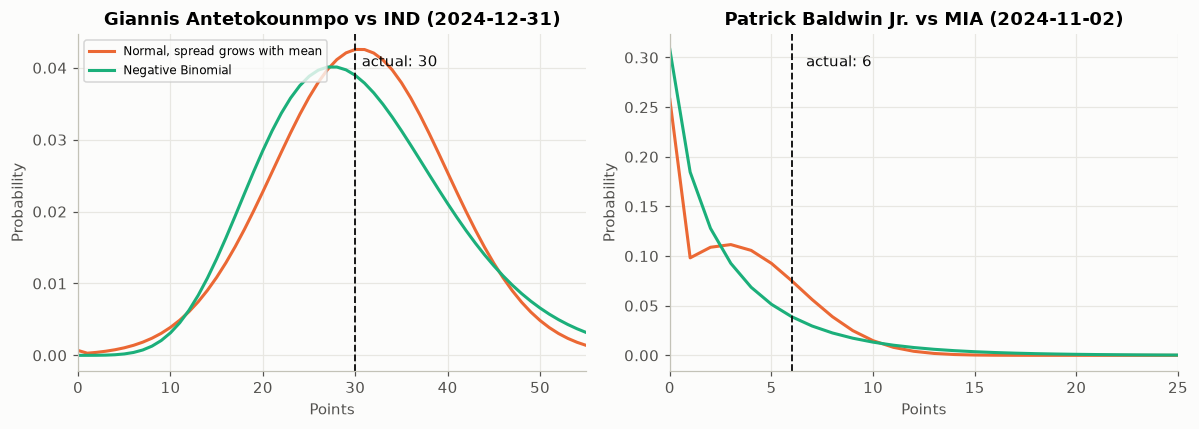

Giannis Antetokounmpo    median 30, 80% range 18-42, P(20+) = 88%, actual 30
Patrick Baldwin Jr.      median 3, 80% range 0-7, P(20+) = 0%, actual 6


In [2]:
star = valid[(valid["PTS_EWM20"] > 27)].iloc[200]
bench = valid[(valid["PTS_EWM20"].between(5, 7))].iloc[200]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, row in zip(axes, [star, bench]):
    one = valid.loc[[row.name]]
    for k in ["normal_scaled", "negbin"]:
        p = models[k].pmf(one)[0]
        ax.plot(POINTS, p, color=COLORS[k], linewidth=2, label=MODELS[k])
    ax.axvline(row["PTS"], color=INK, linestyle="--", linewidth=1.2)
    ax.text(row["PTS"] + 0.7, ax.get_ylim()[1] * 0.9, f"actual: {row['PTS']}", color=INK)
    p30 = models["normal_scaled"].pmf(one)[0][30:].sum()
    ax.set(title=f"{row['PLAYER_NAME']} vs {row['OPPONENT']} ({row['GAME_DATE'].date()})",
           xlabel="Points", ylabel="Probability", xlim=(0, 55 if row is star else 25))
axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

for row in [star, bench]:
    one = valid.loc[[row.name]]
    m = models["normal_scaled"]
    lo, mid, hi = m.quantile(one, 0.1)[0], m.quantile(one, 0.5)[0], m.quantile(one, 0.9)[0]
    print(f"{row['PLAYER_NAME']:<24} median {mid}, 80% range {lo}-{hi}, "
          f"P(20+) = {m.pmf(one)[0][20:].sum():.0%}, actual {row['PTS']}")

**Notice:**
- The Negative Binomial (green) leans left with a longer right tail; the Normal (orange) is symmetric.
- The star's range is much wider than the bench player's - bigger scorers, bigger swings.
- For the bench player, the Normal has a strange spike at 0: a bell curve centered at ~3 puts real probability on *negative*
  points, and all of that gets piled into the "0" bucket. A sign that a symmetric bell is awkward near zero.

## 2. Are the probabilities honest? (calibration)

The key test for a distribution model: when it says "10% chance of being this low," does that happen 10% of the time?

We compute each game's **PIT** = *where the actual result fell inside the predicted distribution* (0 = far below, 1 = far above).
If the model is honest, PIT values are spread **evenly** - a flat histogram. Shapes to watch for:
- **U-shape** -> too many surprises -> ranges too narrow (overconfident)
- **Hump in the middle** -> ranges too wide (underconfident)
- **Tilted** -> the center is biased

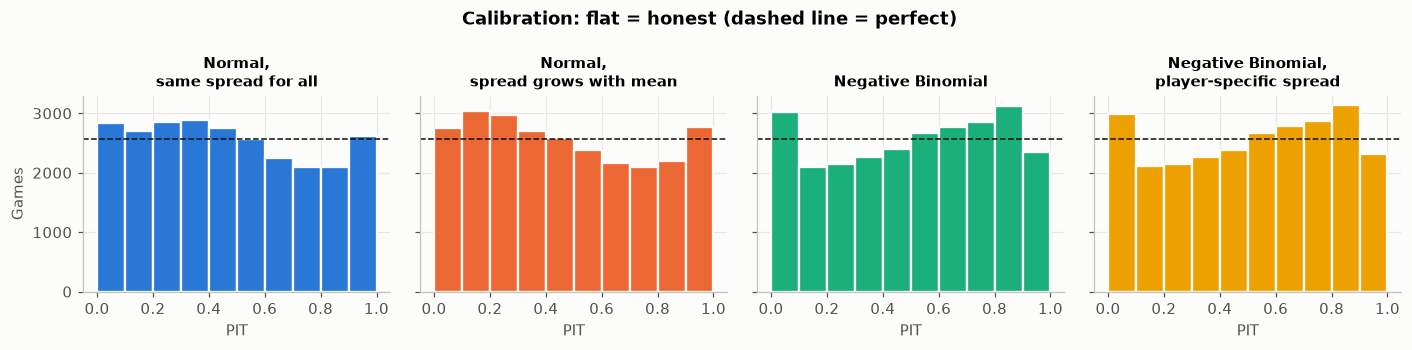

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for ax, (k, pmf) in zip(axes, pmfs.items()):
    pit = randomized_pit(pmf, y)
    ax.hist(pit, bins=10, range=(0, 1), color=COLORS[k], edgecolor="#fcfcfb", linewidth=1.5)
    ax.axhline(len(pit) / 10, color=INK, linestyle="--", linewidth=1)
    ax.set_title(MODELS[k].replace(", ", ",\n"), fontsize=10)
    ax.set_xlabel("PIT")
axes[0].set_ylabel("Games")
fig.suptitle("Calibration: flat = honest (dashed line = perfect)", fontweight="bold")
plt.tight_layout(); plt.show()

None is perfectly flat, and the two shapes fail in **opposite directions**:
- **Normal (orange): tilted toward the left.** Actual results land in the lower part of its range too often. A symmetric bell puts
  its middle (median) at the average, but real scoring is a bit skewed: the median game is slightly *below* the average.
- **Negative Binomial (green): tilted toward the right.** It's *too* skewed, so its median is too low and results land high too often.

So the truth is **in between**: scoring is skewed, but less than a Negative Binomial says. Keep this in mind - it explains everything below.
(The middle 80% still holds ~79-80% of results for all four, so the ranges themselves are honest.)

## 3. Where each shape fails

For an honest model, 10% of results should land **below its 10th percentile** and 10% **above its 90th percentile** - in every group of players.

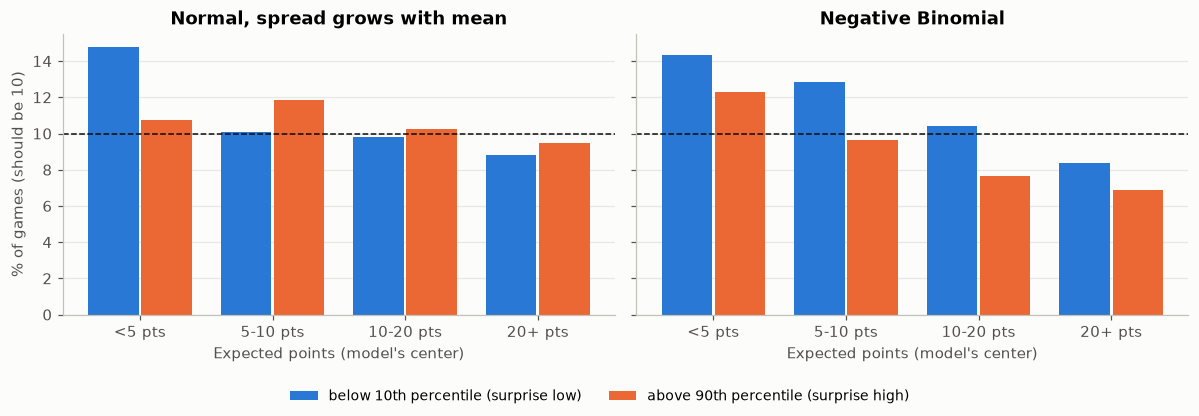

In [4]:
mu = models["negbin"]._mu(valid)
tier = pd.cut(mu, [0, 5, 10, 20, 100], labels=["<5", "5-10", "10-20", "20+"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
x = np.arange(4)
for ax, k in zip(axes, ["normal_scaled", "negbin"]):
    pit = randomized_pit(pmfs[k], y)
    low = pd.Series(pit < 0.1).groupby(tier).mean() * 100
    high = pd.Series(pit > 0.9).groupby(tier).mean() * 100
    ax.bar(x - 0.2, low.values, width=0.38, color=BLUE, label="below 10th percentile (surprise low)")
    ax.bar(x + 0.2, high.values, width=0.38, color=ORANGE, label="above 90th percentile (surprise high)")
    ax.axhline(10, color=INK, linestyle="--", linewidth=1)
    ax.set_xticks(x, [f"{t} pts" for t in low.index])
    ax.set(title=MODELS[k], xlabel="Expected points (model's center)")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("% of games (should be 10)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False, fontsize=9)
plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()

**This is the surprise of the phase.** In Phase 1 we predicted the Negative Binomial would win because scoring is skewed.
But look at the right panel: for mid-level players and stars, only ~7% of games beat its 90th percentile (should be 10%).
Its long right tail expects more explosions than really happen, and it puts too much weight on low games.

Why? Once you know a player's expected points, his actual points are **more symmetric** than a pure count distribution
predicts. Coaches give scorers a steady role, so their nights cluster around their average more than "random counts" would.

**Lesson: the textbook choice was a reasonable guess, but only checking against real data tells you if it's right.**

Both models also struggle with the **lowest group** (<5 expected points): too many surprise-low games. That's the zero problem:

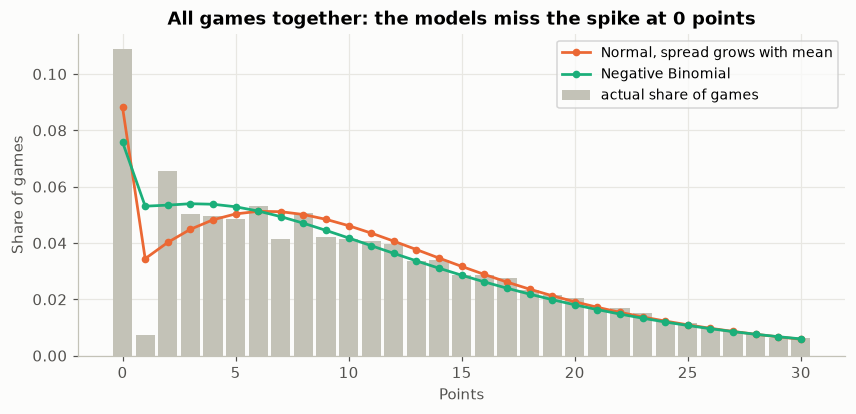

Actual 0-point games: 10.9%   Normal predicts: 8.8%   Negative Binomial predicts: 7.6%


In [5]:
fig, ax = plt.subplots(figsize=(9, 3.8))
actual = np.bincount(y, minlength=K_MAX + 1)[:31] / len(y)
ax.bar(POINTS[:31], actual, color="#c3c2b7", width=0.85, label="actual share of games")
for k in ["normal_scaled", "negbin"]:
    ax.plot(POINTS[:31], pmfs[k].mean(axis=0)[:31], "o-", color=COLORS[k], markersize=4, linewidth=1.8, label=MODELS[k])
ax.set(title="All games together: the models miss the spike at 0 points", xlabel="Points", ylabel="Share of games")
ax.legend(fontsize=9)
plt.show()
print(f"Actual 0-point games: {np.mean(y == 0):.1%}   " +
      "   ".join(f"{MODELS[k].split(',')[0]} predicts: {pmfs[k][:, 0].mean():.1%}" for k in ["normal_scaled", "negbin"]))

Also notice how **lumpy** real scoring is: 1-point games almost never happen (you'd need exactly one made free throw and nothing else),
while 2 points is common. Smooth distributions can't capture that, but it barely matters for most questions.

About 11% of games are 0-point games, but the models expect ~8-9%. Those are mostly bench players who got only a few garbage-time
minutes. No smooth distribution captures that well - it needs a model of **minutes** (will he play 3 minutes or 20?).
That's exactly what the **simulation in Phase 8** will do.

## 4. Over/under: is the probability trustworthy?

Imagine a betting line = his weighted average rounded to x.5. The model says, e.g., "62% chance he goes over."
If we group all games where the model said ~60%, did ~60% actually go over? That's a **reliability diagram** - points on the diagonal = trustworthy.

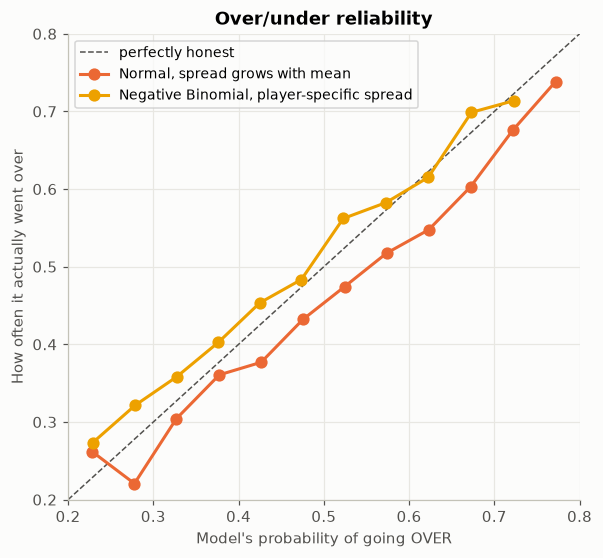

Base rate: 45.7% of games went over the line


In [6]:
line = betting_line(valid)
went_over = (valid["PTS"].to_numpy() > line)
fig, ax = plt.subplots(figsize=(6, 5.5))
ax.plot([0.2, 0.8], [0.2, 0.8], color=INK_2, linestyle="--", linewidth=1, label="perfectly honest")
for k in ["normal_scaled", "negbin_player"]:
    p_over = 1 - np.cumsum(pmfs[k], axis=1)[np.arange(len(y)), np.floor(line).astype(int)]
    bins = pd.cut(p_over, np.arange(0.2, 0.81, 0.05))
    rel = pd.DataFrame({"p": p_over, "o": went_over}).groupby(bins, observed=True).agg(p=("p", "mean"), o=("o", "mean"), n=("o", "size"))
    rel = rel[rel["n"] >= 200]
    ax.plot(rel["p"], rel["o"], "o-", color=COLORS[k], linewidth=2, markersize=7, label=MODELS[k])
ax.set(xlim=(0.2, 0.8), ylim=(0.2, 0.8), xlabel="Model's probability of going OVER", ylabel="How often it actually went over",
       title="Over/under reliability")
ax.legend(fontsize=9, loc="upper left")
plt.show()
print(f"Base rate: {went_over.mean():.1%} of games went over the line")

This is the "opposite tilts" story again:
- **Normal (orange) sits below the diagonal:** it says 62% "over" when the real rate is ~55%. Its median is too high,
  so it overrates the over. That's why it has a worse Brier score despite the best log score.
- **NB player-specific (yellow) is closer to the diagonal**, slightly *underrating* the over (its median is a bit too low).

Both clearly separate likely-overs from likely-unders (real rates go from ~25% to ~72%), which is the useful part.

(Real sportsbook lines are much sharper than "his weighted average", so this is **not** a betting edge - just a calibration check.)

## 5. Scoreboard

In [7]:
scores = pd.read_csv("../results/distribution_scores.csv", index_col=0)
scores.round(4)

,LOG_SCORE,COVER_80,AVG_RANGE_WIDTH,BRIER_OVER
model,,,,
"Normal, same spread for all",-3.0153,0.7873,13.9468,0.2392
"Normal, spread grows with mean",-2.9994,0.7845,14.2025,0.2389
Negative Binomial,-3.0200,0.7909,14.7028,0.2375
"Negative Binomial, player-specific spread",-3.0168,0.7937,14.7983,0.2378


| Metric | Meaning | Best |
|---|---|---|
| LOG_SCORE | avg log-probability given to what happened (higher = better) | **Normal, growing spread** |
| COVER_80 | % inside the 80% range (should be 80%) | all ~79%: honest |
| BRIER_OVER | error of over/under probabilities (lower = better; coin flip = 0.25) | Negative Binomial (by a hair) |

And on the main leaderboard, using a distribution's **median** as the point prediction slightly improves MAE
(4.507 -> ~4.49). Why? MAE is minimized by the *median*, not the mean, and a whole-number prediction suits whole-number points.

## 6. Summary

1. **Spread = model error + game randomness:** variance ~ 5 + 2.7 x expected points. A 25-ppg star has a typical swing of ~9 points.
2. **The 80% ranges are honest** for all models (~79-80% of results inside).
3. **Real scoring is skewed - but less than a Negative Binomial.** The Normal is too symmetric (overrates overs), the NB too skewed
   (too long a right tail). No single winner: Normal for log score, NB for over/under. Checking beat assuming.
4. **3-point-heavy and streaky players really are more unpredictable** (the player-specific model gave them ~15-20% more variance), but it only helps a little.
5. **Weak spots: 0-point games and the exact skew.** Both point to the same fix: simulate the game from its parts
   (minutes -> shots -> makes) instead of picking a textbook shape. -> Phase 8.

**Next (Phase 7): tree models.** They'll try to improve the **center** - finding "it depends" patterns that linear regression can't.